# Hubble with noise: four known moves of ±0.05°

Same as `hubbletilus_noise_moves.ipynb` (tilts of ±0.1°), with **known tilts of ±0.05° about x and about y**, half the size. The secondary has the unknown misalignment of the thesis run, and each of the five positions is observed at the same five fields with independent noise ($\sigma = 0.01$, $10^{-4}$ of the ideal peak, seed 2026).

As in the ±0.1° notebook:
- the likelihood and the DE cost sum over the positions; each position uses the calibration covariance of its field, and the normalization uses the 15 modes;
- the positions, and DE's population, are computed in parallel by worker processes (`hubble_moves_pool.py`, checked against `genpsf` and `lstep` below), and DE uses `updating='deferred'`;
- a DE bound whose posterior range collapses onto a single value (because `ptform` rounds to 0.01) is widened by one rounding step;
- the hard-coded solution cells at the end of `hubbletilus_noise.ipynb` are replaced by a results section.

Different from the ±0.1° notebook:
- a compatibility cell for Optiland 0.6.3. The run uses Optiland 0.6.0, like the thesis and the ±0.1° run, and there the cell does nothing. 0.6.3 refuses the paraxial exit-pupil calculation for tilted or decentered mirrors; the cell makes it warn instead, and with it 0.6.3 reproduces the 0.6.0 Jacobian to $4\times10^{-5}$ but runs about twice as slowly;
- DE runs in this notebook for up to 1000 generations. Creating a file named `STOP_DE_0p05` next to the notebook ends it cleanly after the current generation; it then polishes and the results section runs as usual;
- files: Nautilus checkpoint `hubbletilus_noise_moves_0p05.hdf5`, DE log `solutions_log_noise_moves_0p05.txt`.

The linearized prediction (Chapter 5) for this design is 1.2–1.3 µm on the decenters, against 0.6 µm with ±0.1° moves and 3.6–4.0 µm from the nominal position alone.

In [1]:
from optiland import optic, physical_apertures
from optiland.psf import MMDFTPSF
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import j1
from scipy.special import jv
from scipy.stats import truncnorm
from scipy.optimize import differential_evolution
plt.rcParams['figure.figsize'] = (20,10)
import warnings
warnings.filterwarnings('ignore')
from poppy.zernike import zernike_basis
from nautilus import Sampler
import corner
from optiland.wavefront import OPD
from matplotlib.colors import LogNorm
import pandas as pd

In [3]:
# Optiland 0.6.3 refuses scalar paraxial analysis (used for the exit pupil of the wavefront reference sphere)
# for decentered or tilted mirrors; 0.6.0, used for the thesis, computed the same approximate values without
# the check. Treat every call as a paraxial seed so that 0.6.3 warns instead of raising; with this, 0.6.3
# reproduces the 0.6.0 Jacobian at the truth to 4e-5. hubble_moves_pool.py does the same in the workers.
try:
    import optiland.paraxial_path as _paraxial_path
    _paraxial_path.in_paraxial_seed_scope = lambda: True
except ImportError:  # Optiland 0.6.0 has no such check
    pass

In [2]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [3]:
from functools import lru_cache

# --- drop-in helpers (uses your existing basis_vectors) ---

def _outside_key(outside):
    if outside is None or (isinstance(outside, float) and np.isnan(outside)):
        return "nan"
    return float(outside)

@lru_cache(maxsize=16)
def _polar_grid(npix, zero):
    x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.0) / zero
    xx, yy = np.meshgrid(x, x)
    rho = np.sqrt(xx ** 2 + yy ** 2)
    theta = np.arctan2(yy, xx)
    return rho, theta

@lru_cache(maxsize=16)
def basis_vectors_cached(nterms=15, npix=256, zero=19.053609871416903, outside="nan"):
    """Cached wrapper around basis_vectors. `outside` must be hashable ('nan' or a float)."""
    outside_val = np.nan if outside == "nan" else float(outside)
    rho, theta = _polar_grid(npix, zero)
    return basis_vectors(
        nterms=nterms,
        rho=rho,
        theta=theta,
        outside=outside_val,
        zero=zero,
    )

def clear_basis_cache():
    basis_vectors_cached.cache_clear()
    _polar_grid.cache_clear()

def decompose_psf_cached(psf, nterms=15, outside=np.nan, **kwargs):
    npix = psf.shape[0]
    zero = kwargs.get("zero", 19.053609871416903)
    basis_stack = basis_vectors_cached(
        nterms=nterms,
        npix=npix,
        zero=zero,
        outside=_outside_key(outside),
    )
    basis_flat = basis_stack.reshape(nterms, -1)
    psf_flat = psf.ravel()
    numerators = basis_flat @ psf_flat
    denominators = np.einsum("ij,ij->i", basis_flat, basis_flat)
    return numerators / denominators

In [4]:
def decompose_psf(psf, nterms=10, basis=zernike_basis, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=0.0, **kwargs)
    basis_set = np.array(basis_set)
    basis_flat = basis_set.reshape(nterms, -1)
    numerators = basis_flat @ psf.ravel()
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs

In [5]:
def hubble(WL=0.55,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    #Hubble
    hubble = optic.Optic(name="Hubble")

    hubble.add_surface(index=0, radius=np.inf, thickness=np.inf)

    # add physical aperture in primary mirror
    obscuration = physical_apertures.RadialAperture(r_max=1200, r_min=384)
    c1 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=0, offset_y=1000)
    c2 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=-707.15, offset_y=-707.15)
    c3 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=707.15, offset_y=-707.15)
    r1 = physical_apertures.RectangularAperture(x_min=-19, x_max=19, y_min=-1200, y_max=1200)
    r2 = physical_apertures.RectangularAperture(x_min=-1200, x_max=1200, y_min=-19, y_max=19)

    ap = obscuration - r1 - r2 -c1 - c2 - c3

    hubble.add_surface(
        index=1,
        x=0.0, y=0.0, z=0,   # paraxial / entrance reference
    )

    hubble.add_surface(
        index=2,
        radius=-11040.02286,
        x=0.0, y=0.0, z=4910.01016,
        material="mirror",
        is_stop=True,
        conic=-1.001152,
        aperture=ap,
    )

    hubble.add_surface(
        index=3,
        radius=-1349.31166,
        x=sdx / K,
        y=sdy / K,
        z=0 + sdz / K,              # independent M2 piston
        rx=np.deg2rad(stx),
        ry=np.deg2rad(sty),
        material="mirror",
        conic=-1.483014,
    )

    hubble.add_surface(
        index=4,
        radius=-635.38227,
        x=0.0, y=0.0, z=6365.20955,         # image fixed while M2 moves
    )

    hubble.set_aperture(aperture_type="EPD", value=2400)

    hubble.set_field_type(field_type="angle")
    hubble.add_field(y=0.)
    hubble.add_field(y=0.038)
    hubble.add_field(y=-0.038)

    hubble.add_wavelength(value=WL, is_primary=True)
    
    return hubble

In [6]:
def genpsf(WL=0.55, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field =(0,0)):

    telescope = hubble(WL, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, grid_size=64)
    PSF = psf.psf[96:160,96:160]
    r = decompose_psf_cached(PSF, nterms=dterms)

    return r

In [7]:
def genpsfn(WL=0.55, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field =(0,0)):

    telescope = hubble(WL, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, grid_size=64)
    PSF = psf.psf[96:160,96:160]
    gauss_noise = np.random.normal(0, 0.01, PSF.shape)
    r = decompose_psf_cached(PSF + gauss_noise, nterms=dterms)

    return r

In [8]:
import os
import multiprocessing as mp
import hubble_moves_pool

# Known moves of the secondary relative to the unknown misalignment (sdx, sdy, sdz in um; stx, sty in deg):
# the nominal position and tilts of +-0.05 deg about x and about y
MOVES = np.array([[0, 0, 0, 0, 0],
                  [0, 0, 0, 0.05, 0],
                  [0, 0, 0, -0.05, 0],
                  [0, 0, 0, 0, 0.05],
                  [0, 0, 0, 0, -0.05]])
POSITIONS = ['nominal', 'stx +0.05°', 'stx -0.05°', 'sty +0.05°', 'sty -0.05°']
FIELDS = hubble_moves_pool.FIELDS

# one single-threaded worker per core (the variables only reach the new processes), spawned rather than
# forked because numpy's Accelerate backend is not fork-safe; coeffs_all spreads the positions over the
# workers, and DE spreads its population
for k in ("VECLIB_MAXIMUM_THREADS", "OMP_NUM_THREADS"):
    os.environ[k] = "1"
pool = mp.get_context("spawn").Pool(os.cpu_count())

def coeffs_all(t):
    """Coefficients (positions x fields x 15) with the secondary at t plus each known move."""
    return np.array(pool.map(hubble_moves_pool.position_coeffs, [np.asarray(t, dtype=float) + d for d in MOVES]))

# the workers' copy of the forward model must agree with genpsf above
t = [52.22, -113.86, 38.99, 0.13, -0.04]
serial = np.array([[genpsf(WL=0.55, sdx=t[0] + d[0], sdy=t[1] + d[1], sdz=t[2] + d[2], stx=t[3] + d[3], sty=t[4] + d[4], dterms=15, field=f)
                    for f in FIELDS] for d in MOVES])
print("max |workers - genpsf| =", np.abs(coeffs_all(t) - serial).max())

max |workers - genpsf| = 0.0


In [ ]:
xcy = []

for i in range(10000):
    sx = np.round(np.random.normal(loc=0,scale=100), 2)
    sy = np.round(np.random.normal(loc=0,scale=100), 2)
    sz = np.round(np.random.normal(loc=0,scale=100), 2)
    stx = np.round(np.random.normal(loc=0,scale=0.167), 2)
    sty = np.round(np.random.normal(loc=0,scale=0.167), 2)
    ars = genpsf(WL=0.55, sdx=sx, sdy=sy, sdz=sz, stx=stx, sty=sty, dterms=15, field=(-1, -1))
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [ ]:
xcy = np.array(xcy)

In [ ]:
np.cov(xcy.T)

In [9]:
sdx_true = 52.22#np.round(np.random.normal(loc=0,scale=100), 2)
sdy_true = -113.86#np.round(np.random.normal(loc=0,scale=100), 2)
sdz_true = 38.99#np.round(np.random.normal(loc=0,scale=100), 2)
stx_true = 0.13#np.round(np.random.normal(loc=0,scale=0.167), 2)
sty_true = -0.04#np.round(np.random.normal(loc=0,scale=0.167), 2)

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
np.random.seed(2026)
ct = genpsfn(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)
ctf10 = genpsfn(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,0))
ctf01 = genpsfn(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(0,1))
ctf11 = genpsfn(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,1))
ctfm11 = genpsfn(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(-1,-1))

# PSFs after the known moves; obs[k, f] holds the coefficients at position k and field FIELDS[f]
obs = np.array([[ct, ctf01, ctf10, ctf11, ctfm11]] + [
    [genpsfn(WL=0.55, sdx=sdx_true + d[0], sdy=sdy_true + d[1], sdz=sdz_true + d[2], stx=stx_true + d[3], sty=sty_true + d[4], dterms=15, field=f)
     for f in FIELDS] for d in MOVES[1:]])
print(obs.shape)

52.22 -113.86 38.99 0.13 -0.04
(5, 5, 15)


In [10]:
C = np.array([[ 4.03218647e-02, -3.13123598e-03, -3.91884813e-03,
        -5.00044667e-02, -4.14221437e-03, -2.36261847e-04,
        -3.79298958e-03,  1.23043111e-04, -3.61327819e-05,
         2.03784537e-05, -4.33543253e-02, -1.23631143e-04,
        -2.81279620e-03, -1.36418467e-03,  5.16657065e-04],
       [-3.13123598e-03,  7.06186455e-02,  6.73450340e-03,
         5.54039908e-03,  3.89928934e-03,  6.12802980e-03,
         6.76720480e-03,  9.19119990e-02,  2.29933858e-03,
        -1.84660233e-03,  4.35043662e-03,  5.66652684e-03,
         2.63628550e-03,  7.94167939e-04,  2.95842305e-04],
       [-3.91884813e-03,  6.73450340e-03,  6.84613336e-02,
         7.60205379e-03,  3.75726258e-03, -1.58692793e-03,
         8.76644163e-02,  6.39576703e-03,  3.52397464e-03,
        -3.17898144e-03,  6.47055910e-03, -9.71130673e-04,
         6.04727032e-04, -1.06342792e-03, -8.13790544e-05],
       [-5.00044667e-02,  5.54039908e-03,  7.60205379e-03,
         8.64888692e-02,  6.54291488e-03,  1.68023820e-03,
         8.69942733e-03,  4.70897854e-03,  5.39805343e-04,
         1.10410145e-03,  8.88982515e-02,  1.52035348e-03,
         5.42085727e-03,  2.32633755e-03, -7.37805712e-04],
       [-4.14221437e-03,  3.89928934e-03,  3.75726258e-03,
         6.54291488e-03,  4.45350666e-02, -5.07359893e-04,
         3.17062004e-03,  6.55242327e-03,  1.78061361e-03,
        -3.46487976e-03,  4.82403691e-03, -5.68882447e-04,
         5.30073514e-02, -1.05929968e-03,  4.23122974e-05],
       [-2.36261847e-04,  6.12802980e-03, -1.58692793e-03,
         1.68023820e-03, -5.07359893e-04,  4.14951752e-02,
        -3.71286343e-03,  9.93705642e-03,  8.37386626e-04,
         4.26078067e-03,  2.08621212e-03,  5.29140793e-02,
        -4.49083167e-04,  7.16390141e-04,  7.32459886e-04],
       [-3.79298958e-03,  6.76720480e-03,  8.76644163e-02,
         8.69942733e-03,  3.17062004e-03, -3.71286343e-03,
         1.40400134e-01,  6.87864988e-03,  7.17014736e-03,
        -3.75406236e-03,  8.21398307e-03, -2.71980286e-03,
         1.52596553e-03, -1.61562265e-03,  4.53601602e-04],
       [ 1.23043111e-04,  9.19119990e-02,  6.39576703e-03,
         4.70897854e-03,  6.55242327e-03,  9.93705642e-03,
         6.87864988e-03,  1.47982864e-01,  2.67622097e-03,
        -4.28532317e-03,  5.27171685e-03,  1.02388819e-02,
         6.18249957e-03,  1.00433965e-03,  1.32302057e-04],
       [-3.61327819e-05,  2.29933858e-03,  3.52397464e-03,
         5.39805343e-04,  1.78061361e-03,  8.37386626e-04,
         7.17014736e-03,  2.67622097e-03,  2.23666318e-02,
        -6.26186769e-04,  1.00876396e-03,  2.41575178e-03,
         2.53693270e-03, -8.15784386e-04,  1.01118486e-03],
       [ 2.03784537e-05, -1.84660233e-03, -3.17898144e-03,
         1.10410145e-03, -3.46487976e-03,  4.26078067e-03,
        -3.75406236e-03, -4.28532317e-03, -6.26186769e-04,
         2.36689036e-02,  1.53293363e-03,  5.75182129e-03,
        -3.46522819e-03,  1.66998871e-03,  1.14732743e-03],
       [-4.33543253e-02,  4.35043662e-03,  6.47055910e-03,
         8.88982515e-02,  4.82403691e-03,  2.08621212e-03,
         8.21398307e-03,  5.27171685e-03,  1.00876396e-03,
         1.53293363e-03,  1.06099856e-01,  2.15689629e-03,
         4.88797248e-03,  3.05465732e-03, -9.01518426e-04],
       [-1.23631143e-04,  5.66652684e-03, -9.71130673e-04,
         1.52035348e-03, -5.68882447e-04,  5.29140793e-02,
        -2.71980286e-03,  1.02388819e-02,  2.41575178e-03,
         5.75182129e-03,  2.15689629e-03,  8.54539506e-02,
        -7.98993553e-04,  6.41557868e-04,  1.00352855e-03],
       [-2.81279620e-03,  2.63628550e-03,  6.04727032e-04,
         5.42085727e-03,  5.30073514e-02, -4.49083167e-04,
         1.52596553e-03,  6.18249957e-03,  2.53693270e-03,
        -3.46522819e-03,  4.88797248e-03, -7.98993553e-04,
         7.55857248e-02, -1.12282961e-03, -2.15156673e-04],
       [-1.36418467e-03,  7.94167939e-04, -1.06342792e-03,
         2.32633755e-03, -1.05929968e-03,  7.16390141e-04,
        -1.61562265e-03,  1.00433965e-03, -8.15784386e-04,
         1.66998871e-03,  3.05465732e-03,  6.41557868e-04,
        -1.12282961e-03,  1.59609647e-02,  3.78869986e-04],
       [ 5.16657065e-04,  2.95842305e-04, -8.13790544e-05,
        -7.37805712e-04,  4.23122974e-05,  7.32459886e-04,
         4.53601602e-04,  1.32302057e-04,  1.01118486e-03,
         1.14732743e-03, -9.01518426e-04,  1.00352855e-03,
        -2.15156673e-04,  3.78869986e-04,  1.55326304e-02]])

Cf10 = np.array([[ 3.30305073e-02, -2.97945873e-04, -1.41200698e-03,
        -4.69891560e-02,  3.33393844e-04,  1.66881570e-03,
        -1.39401337e-03,  1.87190805e-03, -1.27602332e-03,
         7.31928722e-04, -4.25996175e-02,  3.46031732e-04,
         9.89367483e-04,  1.96468978e-04,  4.13360804e-04],
       [-2.97945873e-04,  6.06267130e-02,  9.61964489e-04,
         2.08511877e-03,  7.16207715e-03,  1.49095285e-03,
        -1.27799313e-05,  8.50807347e-02, -1.42606855e-03,
        -2.61227098e-03,  2.23000100e-03, -1.18195630e-03,
         5.49994539e-03,  4.81006621e-04,  6.92638322e-04],
       [-1.41200698e-03,  9.61964489e-04,  6.78661251e-02,
         6.28287374e-03,  4.11628769e-04, -1.09013010e-03,
         9.22514395e-02, -6.74592922e-04,  2.25619844e-03,
        -8.11538609e-04,  6.37131882e-03, -1.49841132e-03,
        -1.61500632e-04,  1.11089740e-06, -2.43792200e-04],
       [-4.69891560e-02,  2.08511877e-03,  6.28287374e-03,
         8.68046615e-02, -8.68630060e-04, -2.53465029e-03,
         7.72958496e-03,  7.13254215e-04,  1.93279142e-03,
        -1.34115629e-03,  9.06463543e-02, -4.45781268e-04,
        -1.64472044e-03,  4.01565721e-04, -9.15431699e-04],
       [ 3.33393844e-04,  7.16207715e-03,  4.11628769e-04,
        -8.68630060e-04,  4.30171572e-02, -1.63759912e-03,
         1.17718130e-03,  8.92745556e-03, -6.80845752e-04,
        -1.48325635e-03, -1.32984830e-03, -2.29702861e-03,
         5.25623310e-02,  1.02161448e-04,  9.82848165e-04],
       [ 1.66881570e-03,  1.49095285e-03, -1.09013010e-03,
        -2.53465029e-03, -1.63759912e-03,  4.12480245e-02,
        -4.30396208e-03,  2.60696004e-03,  4.41795206e-03,
         5.43790247e-04, -1.92803131e-03,  5.39377905e-02,
        -1.74705295e-03, -1.13666608e-05, -1.48725686e-05],
       [-1.39401337e-03, -1.27799313e-05,  9.22514395e-02,
         7.72958496e-03,  1.17718130e-03, -4.30396208e-03,
         1.48824533e-01, -1.72770770e-03,  4.73105063e-03,
        -9.76154835e-04,  8.81995767e-03, -4.84360005e-03,
         9.87883155e-04,  3.07805021e-04, -5.64178781e-04],
       [ 1.87190805e-03,  8.50807347e-02, -6.74592922e-04,
         7.13254215e-04,  8.92745556e-03,  2.60696004e-03,
        -1.72770770e-03,  1.41246368e-01, -2.49739422e-03,
        -5.41233690e-03,  2.54122073e-03, -5.34478109e-04,
         8.51419493e-03,  2.47819294e-04,  8.94993511e-04],
       [-1.27602332e-03, -1.42606855e-03,  2.25619844e-03,
         1.93279142e-03, -6.80845752e-04,  4.41795206e-03,
         4.73105063e-03, -2.49739422e-03,  2.38544809e-02,
         6.42031686e-04,  1.41276509e-03,  4.81901139e-03,
        -2.47661242e-04, -1.49160858e-03,  3.49816395e-04],
       [ 7.31928722e-04, -2.61227098e-03, -8.11538609e-04,
        -1.34115629e-03, -1.48325635e-03,  5.43790247e-04,
        -9.76154835e-04, -5.41233690e-03,  6.42031686e-04,
         2.14861652e-02, -1.71295340e-03,  2.03640366e-03,
        -2.69099582e-03,  4.14710713e-04,  3.71352184e-04],
       [-4.25996175e-02,  2.23000100e-03,  6.37131882e-03,
         9.06463543e-02, -1.32984830e-03, -1.92803131e-03,
         8.81995767e-03,  2.54122073e-03,  1.41276509e-03,
        -1.71295340e-03,  1.07778520e-01,  3.89138663e-04,
        -2.30091717e-03,  1.19666034e-03, -1.06736947e-03],
       [ 3.46031732e-04, -1.18195630e-03, -1.49841132e-03,
        -4.45781268e-04, -2.29702861e-03,  5.39377905e-02,
        -4.84360005e-03, -5.34478109e-04,  4.81901139e-03,
         2.03640366e-03,  3.89138663e-04,  8.77423320e-02,
        -3.04900469e-03,  6.41936241e-04, -1.77473848e-06],
       [ 9.89367483e-04,  5.49994539e-03, -1.61500632e-04,
        -1.64472044e-03,  5.25623310e-02, -1.74705295e-03,
         9.87883155e-04,  8.51419493e-03, -2.47661242e-04,
        -2.69099582e-03, -2.30091717e-03, -3.04900469e-03,
         7.59748362e-02,  1.95926917e-04,  1.11368465e-03],
       [ 1.96468978e-04,  4.81006621e-04,  1.11089740e-06,
         4.01565721e-04,  1.02161448e-04, -1.13666608e-05,
         3.07805021e-04,  2.47819294e-04, -1.49160858e-03,
         4.14710713e-04,  1.19666034e-03,  6.41936241e-04,
         1.95926917e-04,  1.60304869e-02, -7.83392842e-06],
       [ 4.13360804e-04,  6.92638322e-04, -2.43792200e-04,
        -9.15431699e-04,  9.82848165e-04, -1.48725686e-05,
        -5.64178781e-04,  8.94993511e-04,  3.49816395e-04,
         3.71352184e-04, -1.06736947e-03, -1.77473848e-06,
         1.11368465e-03, -7.83392842e-06,  1.50280899e-02]])
 
Cf01 = np.array([[ 3.92414131e-02, -5.92011510e-06,  3.30924557e-03,
        -4.91343324e-02, -8.53216272e-04, -2.15114794e-03,
         4.80842810e-03,  1.83791535e-03,  1.61193303e-04,
         1.17572076e-04, -4.28772616e-02, -1.46853640e-03,
        -2.52304923e-04, -5.65704230e-04,  5.23100679e-04],
       [-5.92011510e-06,  6.87219733e-02,  9.86879761e-04,
         2.78385461e-03, -3.09775687e-03, -4.39669984e-05,
        -4.26117821e-04,  8.75241062e-02, -2.26375530e-03,
        -1.85521119e-03,  4.36456468e-03,  8.04202738e-04,
        -3.90473066e-03, -5.56540254e-05, -4.56925907e-04],
       [ 3.30924557e-03,  9.86879761e-04,  6.37703827e-02,
        -3.22484631e-03,  4.77605322e-03,  2.84435088e-04,
         8.51161323e-02, -4.33448342e-04,  3.53243706e-03,
        -2.47672827e-04, -1.87403333e-03,  1.15182357e-03,
         3.55095412e-03, -5.50599972e-04,  2.10272024e-04],
       [-4.91343324e-02,  2.78385461e-03, -3.22484631e-03,
         8.55172548e-02, -6.47131079e-04,  1.73146678e-03,
        -4.37626424e-03,  3.37550866e-03, -8.57905586e-04,
         2.76003485e-04,  8.89859039e-02,  1.24885366e-03,
        -1.76845745e-03,  1.03282709e-03, -7.11509028e-04],
       [-8.53216272e-04, -3.09775687e-03,  4.77605322e-03,
        -6.47131079e-04,  4.16562144e-02, -1.41010997e-03,
         8.06907919e-03, -2.05830465e-03,  2.04631099e-03,
        -1.08770332e-03, -1.48965497e-03, -8.42647844e-04,
         5.06462808e-02,  4.11429087e-05,  7.75175225e-04],
       [-2.15114794e-03, -4.39669984e-05,  2.84435088e-04,
         1.73146678e-03, -1.41010997e-03,  3.92848986e-02,
        -7.37569135e-04,  3.56930080e-03, -5.23981097e-04,
         3.21296139e-03,  9.25171393e-04,  5.14650092e-02,
        -9.39940924e-04,  2.52641950e-05,  3.89692385e-04],
       [ 4.80842810e-03, -4.26117821e-04,  8.51161323e-02,
        -4.37626424e-03,  8.06907919e-03, -7.37569135e-04,
         1.38881531e-01, -1.75405346e-03,  6.24210464e-03,
         2.40576101e-04, -2.97713925e-03, -8.09730371e-04,
         7.60742220e-03, -8.99740057e-04,  6.32926155e-04],
       [ 1.83791535e-03,  8.75241062e-02, -4.33448342e-04,
         3.37550866e-03, -2.05830465e-03,  3.56930080e-03,
        -1.75405346e-03,  1.40633466e-01, -2.78874246e-03,
        -4.58964265e-03,  5.41775147e-03,  5.11447073e-03,
        -2.47063242e-03,  7.78790092e-05, -8.86692071e-04],
       [ 1.61193303e-04, -2.26375530e-03,  3.53243706e-03,
        -8.57905586e-04,  2.04631099e-03, -5.23981097e-04,
         6.24210464e-03, -2.78874246e-03,  2.22702283e-02,
        -7.24620712e-04, -5.42286832e-04,  6.52793864e-05,
         3.51310395e-03, -2.99574016e-04,  1.49430300e-03],
       [ 1.17572076e-04, -1.85521119e-03, -2.47672827e-04,
         2.76003485e-04, -1.08770332e-03,  3.21296139e-03,
         2.40576101e-04, -4.58964265e-03, -7.24620712e-04,
         2.04224046e-02,  6.34153490e-04,  4.38127270e-03,
        -2.57660350e-03,  5.65849379e-04,  1.90888589e-04],
       [-4.28772616e-02,  4.36456468e-03, -1.87403333e-03,
         8.89859039e-02, -1.48965497e-03,  9.25171393e-04,
        -2.97713925e-03,  5.41775147e-03, -5.42286832e-04,
         6.34153490e-04,  1.06405156e-01,  4.05503497e-04,
        -2.73159299e-03,  1.60087825e-03, -4.60278489e-04],
       [-1.46853640e-03,  8.04202738e-04,  1.15182357e-03,
         1.24885366e-03, -8.42647844e-04,  5.14650092e-02,
        -8.09730371e-04,  5.11447073e-03,  6.52793864e-05,
         4.38127270e-03,  4.05503497e-04,  8.37580207e-02,
        -1.95568163e-04,  2.17255220e-04,  1.47066446e-04],
       [-2.52304923e-04, -3.90473066e-03,  3.55095412e-03,
        -1.76845745e-03,  5.06462808e-02, -9.39940924e-04,
         7.60742220e-03, -2.47063242e-03,  3.51310395e-03,
        -2.57660350e-03, -2.73159299e-03, -1.95568163e-04,
         7.32585474e-02,  6.28969662e-05,  8.22938934e-04],
       [-5.65704230e-04, -5.56540254e-05, -5.50599972e-04,
         1.03282709e-03,  4.11429087e-05,  2.52641950e-05,
        -8.99740057e-04,  7.78790092e-05, -2.99574016e-04,
         5.65849379e-04,  1.60087825e-03,  2.17255220e-04,
         6.28969662e-05,  1.52824410e-02,  3.25483962e-04],
       [ 5.23100679e-04, -4.56925907e-04,  2.10272024e-04,
        -7.11509028e-04,  7.75175225e-04,  3.89692385e-04,
         6.32926155e-04, -8.86692071e-04,  1.49430300e-03,
         1.90888589e-04, -4.60278489e-04,  1.47066446e-04,
         8.22938934e-04,  3.25483962e-04,  1.57903440e-02]])

Cf11 = np.array([[ 3.66700769e-02, -4.63582020e-03,  8.18935733e-04,
        -4.82426879e-02, -1.10488996e-03,  5.03972399e-05,
        -2.63955561e-04, -2.20035160e-03,  2.04095116e-03,
        -1.43123081e-03, -4.17151544e-02,  1.84961302e-03,
        -6.32837728e-04, -3.44835403e-04,  2.14674052e-04],
       [-4.63582020e-03,  6.67313674e-02,  2.09928588e-03,
         6.94784203e-03, -2.58865983e-03,  5.83866239e-03,
         1.19906324e-03,  8.30299266e-02,  7.17418255e-04,
        -2.00344159e-03,  5.01664168e-03,  3.53922943e-03,
        -2.95476694e-03,  5.81151041e-04, -3.53527734e-04],
       [ 8.18935733e-04,  2.09928588e-03,  6.90116528e-02,
         4.36568620e-03,  2.33930481e-03, -8.57256483e-03,
         9.17115778e-02,  1.27195057e-03, -9.79153915e-04,
        -9.64306915e-04,  5.27436617e-03, -9.07929689e-03,
         1.18269478e-03,  6.56037990e-04, -7.65782167e-04],
       [-4.82426879e-02,  6.94784203e-03,  4.36568620e-03,
         8.54961081e-02,  1.80027342e-03, -3.28341681e-03,
         6.49423797e-03,  6.67917693e-03, -4.19735617e-03,
         1.26354382e-03,  8.82203288e-02, -5.84060483e-03,
         1.04324143e-03,  1.45010636e-03,  1.10788503e-04],
       [-1.10488996e-03, -2.58865983e-03,  2.33930481e-03,
         1.80027342e-03,  4.13404928e-02, -5.43639108e-04,
         4.35430649e-03, -1.08001526e-03,  1.82482593e-03,
        -3.35335986e-03,  9.29109512e-04, -3.79540145e-04,
         4.88878455e-02, -5.69082176e-04, -4.79887993e-04],
       [ 5.03972399e-05,  5.83866239e-03, -8.57256483e-03,
        -3.28341681e-03, -5.43639108e-04,  4.27537229e-02,
        -1.28176095e-02,  6.94498132e-03,  1.39254603e-03,
         2.17027330e-03, -4.61323559e-03,  5.59618347e-02,
        -1.13892864e-04, -2.57714005e-04,  6.81176196e-05],
       [-2.63955561e-04,  1.19906324e-03,  9.17115778e-02,
         6.49423797e-03,  4.35430649e-03, -1.28176095e-02,
         1.49372038e-01,  1.01344636e-03, -7.99376919e-04,
        -4.75717868e-04,  8.59743065e-03, -1.58089843e-02,
         3.78441407e-03,  1.53601071e-03, -8.29324538e-04],
       [-2.20035160e-03,  8.30299266e-02,  1.27195057e-03,
         6.67917693e-03, -1.08001526e-03,  6.94498132e-03,
         1.01344636e-03,  1.32737547e-01,  1.01952649e-03,
        -4.68975073e-03,  6.70966393e-03,  5.93867992e-03,
        -1.24642682e-03,  9.87397332e-04, -8.18392201e-04],
       [ 2.04095116e-03,  7.17418255e-04, -9.79153915e-04,
        -4.19735617e-03,  1.82482593e-03,  1.39254603e-03,
        -7.99376919e-04,  1.01952649e-03,  2.18595035e-02,
         1.15313233e-04, -4.62586407e-03,  2.56584637e-03,
         2.39222956e-03, -1.28292561e-03,  1.00705938e-03],
       [-1.43123081e-03, -2.00344159e-03, -9.64306915e-04,
         1.26354382e-03, -3.35335986e-03,  2.17027330e-03,
        -4.75717868e-04, -4.68975073e-03,  1.15313233e-04,
         2.21954201e-02,  8.63655421e-04,  3.43692072e-03,
        -4.23816452e-03,  5.89689184e-04,  7.01323249e-04],
       [-4.17151544e-02,  5.01664168e-03,  5.27436617e-03,
         8.82203288e-02,  9.29109512e-04, -4.61323559e-03,
         8.59743065e-03,  6.70966393e-03, -4.62586407e-03,
         8.63655421e-04,  1.05668873e-01, -6.70150507e-03,
         6.63987851e-04,  2.72197839e-03,  3.34309752e-04],
       [ 1.84961302e-03,  3.53922943e-03, -9.07929689e-03,
        -5.84060483e-03, -3.79540145e-04,  5.59618347e-02,
        -1.58089843e-02,  5.93867992e-03,  2.56584637e-03,
         3.43692072e-03, -6.70150507e-03,  9.12522572e-02,
         6.42571757e-04, -3.28642730e-04, -1.76791918e-04],
       [-6.32837728e-04, -2.95476694e-03,  1.18269478e-03,
         1.04324143e-03,  4.88878455e-02, -1.13892864e-04,
         3.78441407e-03, -1.24642682e-03,  2.39222956e-03,
        -4.23816452e-03,  6.63987851e-04,  6.42571757e-04,
         7.07225554e-02, -5.45413159e-04, -9.24949018e-04],
       [-3.44835403e-04,  5.81151041e-04,  6.56037990e-04,
         1.45010636e-03, -5.69082176e-04, -2.57714005e-04,
         1.53601071e-03,  9.87397332e-04, -1.28292561e-03,
         5.89689184e-04,  2.72197839e-03, -3.28642730e-04,
        -5.45413159e-04,  1.63007601e-02, -1.33888293e-04],
       [ 2.14674052e-04, -3.53527734e-04, -7.65782167e-04,
         1.10788503e-04, -4.79887993e-04,  6.81176196e-05,
        -8.29324538e-04, -8.18392201e-04,  1.00705938e-03,
         7.01323249e-04,  3.34309752e-04, -1.76791918e-04,
        -9.24949018e-04, -1.33888293e-04,  1.52706665e-02]])

Cfm11 = np.array([[ 3.37365523e-02, -1.41873801e-03, -1.94999102e-03,
        -4.54296080e-02, -8.25698046e-04,  9.57708407e-04,
        -6.72991106e-04, -2.50343969e-03, -8.64447785e-04,
         7.65512381e-04, -4.07992845e-02,  7.67795946e-04,
        -4.59005340e-04, -1.13228414e-03, -1.14480472e-04],
       [-1.41873801e-03,  6.19584284e-02, -7.09027733e-04,
         5.97194430e-03,  5.76341148e-03,  1.76368619e-03,
         9.53191738e-04,  8.25653722e-02,  1.89018318e-03,
        -2.82285495e-03,  6.85072723e-03,  2.22542738e-03,
         3.27407149e-03, -6.99146018e-04,  7.23854260e-04],
       [-1.94999102e-03, -7.09027733e-04,  6.24532567e-02,
         5.77596530e-03,  6.42150100e-03, -2.05954668e-03,
         8.60659748e-02,  1.26645596e-03,  9.27782832e-04,
        -1.18635176e-03,  4.73575662e-03, -1.92313826e-04,
         5.86389241e-03, -4.02958001e-04, -3.64976413e-04],
       [-4.54296080e-02,  5.97194430e-03,  5.77596530e-03,
         8.20352693e-02,  2.29481744e-03, -2.53830175e-03,
         5.16791295e-03,  9.30955117e-03,  1.52060547e-03,
        -1.62879687e-03,  8.66163516e-02, -2.61991126e-03,
         2.18371353e-03,  2.56660518e-03, -1.29551506e-04],
       [-8.25698046e-04,  5.76341148e-03,  6.42150100e-03,
         2.29481744e-03,  4.06488880e-02,  1.19793216e-03,
         1.00290412e-02,  7.30980737e-03,  4.23510969e-03,
        -3.04404169e-03,  2.75655292e-03,  8.70336845e-04,
         4.82666200e-02, -8.42241066e-04, -1.67967204e-04],
       [ 9.57708407e-04,  1.76368619e-03, -2.05954668e-03,
        -2.53830175e-03,  1.19793216e-03,  4.03638807e-02,
        -2.71683579e-03,  3.84280230e-03,  1.58783133e-03,
         1.65735437e-03, -2.23164216e-03,  5.26035200e-02,
         7.14120615e-04, -3.78074462e-04,  6.91320480e-04],
       [-6.72991106e-04,  9.53191738e-04,  8.60659748e-02,
         5.16791295e-03,  1.00290412e-02, -2.71683579e-03,
         1.41937833e-01,  3.09901513e-03,  2.24003383e-03,
        -2.40447771e-03,  5.17933959e-03, -1.07975787e-03,
         1.06930664e-02, -1.10313547e-03, -5.86203295e-04],
       [-2.50343969e-03,  8.25653722e-02,  1.26645596e-03,
         9.30955117e-03,  7.30980737e-03,  3.84280230e-03,
         3.09901513e-03,  1.37943026e-01,  2.93481392e-03,
        -5.76270288e-03,  1.10933529e-02,  4.84185724e-03,
         5.09374169e-03, -1.37547001e-03,  1.16178657e-03],
       [-8.64447785e-04,  1.89018318e-03,  9.27782832e-04,
         1.52060547e-03,  4.23510969e-03,  1.58783133e-03,
         2.24003383e-03,  2.93481392e-03,  2.12466818e-02,
        -1.80399663e-04,  1.58434987e-03,  2.76710632e-03,
         5.06929736e-03, -7.69212434e-04,  1.30149042e-03],
       [ 7.65512381e-04, -2.82285495e-03, -1.18635176e-03,
        -1.62879687e-03, -3.04404169e-03,  1.65735437e-03,
        -2.40447771e-03, -5.76270288e-03, -1.80399663e-04,
         2.20307605e-02, -1.87677385e-03,  2.29690637e-03,
        -3.35575201e-03,  1.04804843e-03,  9.11104740e-04],
       [-4.07992845e-02,  6.85072723e-03,  4.73575662e-03,
         8.66163516e-02,  2.75655292e-03, -2.23164216e-03,
         5.17933959e-03,  1.10933529e-02,  1.58434987e-03,
        -1.87677385e-03,  1.05630354e-01, -2.46276154e-03,
         3.54758598e-03,  3.76373773e-03, -3.64888853e-04],
       [ 7.67795946e-04,  2.22542738e-03, -1.92313826e-04,
        -2.61991126e-03,  8.70336845e-04,  5.26035200e-02,
        -1.07975787e-03,  4.84185724e-03,  2.76710632e-03,
         2.29690637e-03, -2.46276154e-03,  8.71836858e-02,
         1.00727537e-04, -2.78905146e-04,  1.06507170e-03],
       [-4.59005340e-04,  3.27407149e-03,  5.86389241e-03,
         2.18371353e-03,  4.82666200e-02,  7.14120615e-04,
         1.06930664e-02,  5.09374169e-03,  5.06929736e-03,
        -3.35575201e-03,  3.54758598e-03,  1.00727537e-04,
         6.96275053e-02, -6.08789757e-04, -2.40624978e-04],
       [-1.13228414e-03, -6.99146018e-04, -4.02958001e-04,
         2.56660518e-03, -8.42241066e-04, -3.78074462e-04,
        -1.10313547e-03, -1.37547001e-03, -7.69212434e-04,
         1.04804843e-03,  3.76373773e-03, -2.78905146e-04,
        -6.08789757e-04,  1.50621714e-02, -2.76888524e-05],
       [-1.14480472e-04,  7.23854260e-04, -3.64976413e-04,
        -1.29551506e-04, -1.67967204e-04,  6.91320480e-04,
        -5.86203295e-04,  1.16178657e-03,  1.30149042e-03,
         9.11104740e-04, -3.64888853e-04,  1.06507170e-03,
        -2.40624978e-04, -2.76888524e-05,  1.54223300e-02]])

Cinv = np.linalg.inv(C)  # precision matrix
Cf10inv = np.linalg.inv(Cf10)
Cf01inv = np.linalg.inv(Cf01)
Cf11inv = np.linalg.inv(Cf11)
Cfm11inv = np.linalg.inv(Cfm11)
lnorm = -0.5 * (np.log(np.array(2*np.pi)) * 15 + np.log(np.linalg.det(C)))  # ln(normalization)
lnormf10 = -0.5 * (np.log(np.array(2*np.pi)) * 15 + np.log(np.linalg.det(Cf10))) 
lnormf01 = -0.5 * (np.log(np.array(2*np.pi)) * 15 + np.log(np.linalg.det(Cf01))) 
lnormf11 = -0.5 * (np.log(np.array(2*np.pi)) * 15 + np.log(np.linalg.det(Cf11))) 
lnormfm11 = -0.5 * (np.log(np.array(2*np.pi)) * 15 + np.log(np.linalg.det(Cfm11))) 

# log-likelihood, summed over the mirror positions; every position uses the calibration covariance of its field
CINV = [Cinv, Cf01inv, Cf10inv, Cf11inv, Cfm11inv]
LNORM = lnorm + lnormf01 + lnormf10 + lnormf11 + lnormfm11

def loglike(theta):
    r = coeffs_all(theta) - obs
    return len(MOVES) * LNORM - 0.5 * sum(r[k, f] @ CINV[f] @ r[k, f] for k in range(len(MOVES)) for f in range(len(FIELDS)))
# prior transform
def ptform(utheta):

    usx,usy,usz,ustx,usty = utheta

    xsx =  np.round((200. * (2. * usx - 1.)), decimals=2)
    xsy =  np.round((200. * (2. * usy - 1.)), decimals=2)
    xsz =  np.round((200. * (2. * usz - 1.)), decimals=2)
    xstx =  np.round((0.167 * (2. * ustx - 1.)), decimals=2)
    xsty =  np.round((0.167 * (2. * usty - 1.)), decimals=2)

    return xsx,xsy,xsz,xstx,xsty

In [11]:
len(MOVES) * (lnorm+lnormf01+lnormf10+lnormf11+lnormfm11)

np.float64(351.0560559412555)

In [12]:
loglike([sdx_true, sdy_true, sdz_true, stx_true, sty_true])

np.float64(351.04597702226505)

In [13]:
sampler = Sampler(ptform, loglike, n_dim=5, filepath="hubbletilus_noise_moves_0p05.hdf5")
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 23     | 1        | 8        | 60900    | N/A    | 14306 | +338.22  


np.True_

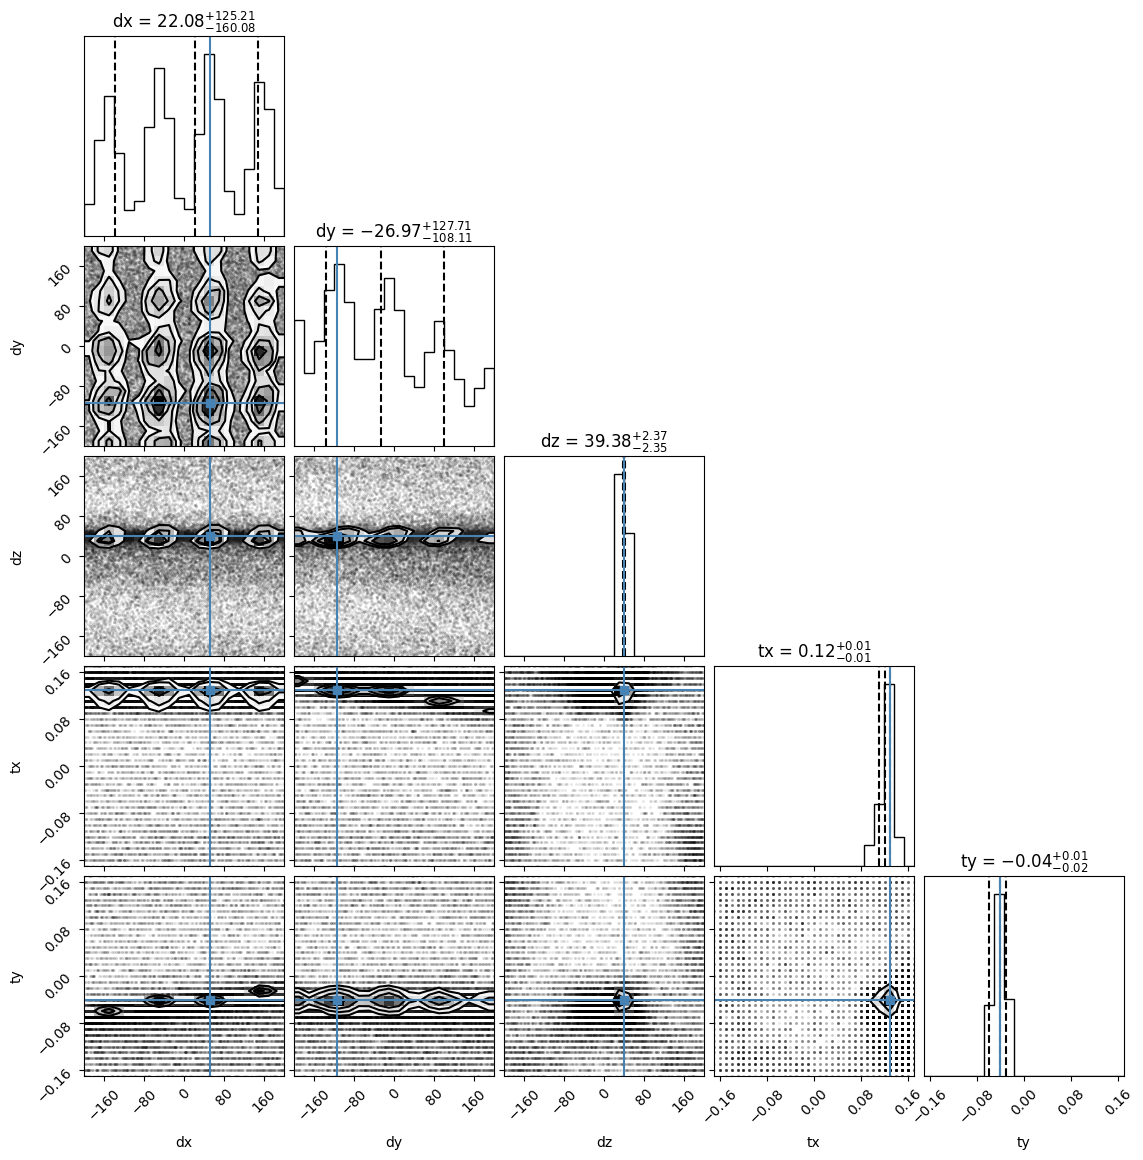

In [14]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['dx', 'dy', 'dz', 'tx', 'ty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    truths=[sdx_true, sdy_true, sdz_true, stx_true, sty_true])

In [15]:
x0 = [np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,4], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')]

In [16]:
x0

[array(51.05), array(-111.11), array(39.15), array(0.13), array(-0.04)]

In [17]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

52.22 -113.86 38.99 0.13 -0.04


In [18]:
def lstep(t):
    return np.sum((obs - coeffs_all(t))**2)

# the same cost as a module function, so that DE can evaluate its population in the worker processes
print("lstep - lstep_moves at x0:", lstep(x0) - hubble_moves_pool.lstep_moves(np.array(x0, dtype=float), MOVES, obs))

lstep - lstep_moves at x0: 0.0


In [19]:
bounds = [(np.quantile(points[-100:,0], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,4], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,4], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

# ptform rounds every parameter to 0.01, so when the posterior is narrower than that (here, the tilts) all of
# the top 100 points share one value and the range collapses; scipy would then hold the parameter fixed at it.
# Widen such a range by one rounding step on each side.
bounds = [(lo - 0.01, hi + 0.01) if lo == hi else (lo, hi) for lo, hi in bounds]

In [20]:
bounds

[(array(-59.44), array(160.14)),
 (array(-127.08), array(-1.7)),
 (array(37.82), array(40.31)),
 (array(0.12), array(0.13)),
 (array(-0.05), array(-0.03))]

In [21]:
history = []

def my_callback(intermediate_result):
    # intermediate_result is an OptimizeResult object
    history.append((intermediate_result.fun, intermediate_result.x.copy()))
    with open("solutions_log_noise_moves_0p05.txt", "a") as f:
        f.write(f"Objective: {intermediate_result.fun}, Best X: {' '.join(f'{v:.10g}' for v in intermediate_result.x)}\n")
    if os.path.exists("STOP_DE_0p05"):
        print(f"Stopping: found STOP_DE_0p05 after generation {len(history)}")
        return True
    if intermediate_result.fun <= 1e-15:
        print(f"Terminating: reached objective value {intermediate_result.fun}")
        return True  # Returns True to halt optimization
    return False

In [22]:
from functools import partial

# the population of each generation is evaluated in parallel on all cores, which needs deferred updating;
# creating the file STOP_DE_0p05 next to this notebook ends DE after the current generation (it then polishes)
result = differential_evolution(hubble_moves_pool.lstep_moves, bounds, args=(MOVES, obs), callback = my_callback, x0 = x0, tol=1e-12, maxiter=1000,
                                updating='deferred', workers=partial(pool.map, chunksize=1))
print(result.x)
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
print(result.nit, "generations:", result.message)

[ 5.42682528e+01 -1.11874493e+02  3.90051911e+01  1.29811187e-01
 -3.98096671e-02]
52.22 -113.86 38.99 0.13 -0.04
1000 generations: Maximum number of iterations has been exceeded.


## Results

The DE estimate is compared with the truth and with the linearized noise-limited errors of Chapter 5, for these five positions and for the nominal position alone, and then with the ±0.1° run. The thesis run (`hubbletilus_noise.ipynb`) used the nominal position only and a different noise realization.

In [23]:
# Linearized noise-limited errors (Chapter 5): Cov = A N A^T, with the Jacobian at the truth
truth = np.array([sdx_true, sdy_true, sdz_true, stx_true, sty_true])
steps = np.array([0.2, 0.2, 0.2, 2e-5, 2e-5])
J = np.zeros((len(MOVES), len(FIELDS) * 15, 5))
for j, h in enumerate(steps):
    e = np.zeros(5)
    e[j] = h
    J[:, :, j] = (coeffs_all(truth + e) - coeffs_all(truth - e)).reshape(len(MOVES), -1) / (2 * h)

B = basis_vectors_cached(nterms=15, npix=64).reshape(15, -1)
G = B @ B.T
N = 0.01**2 * G / np.outer(np.diag(G), np.diag(G))
N_all = np.kron(np.eye(len(FIELDS)), N)

def predicted(Js):
    """Standard deviations, correlation matrix and expected minimum DE cost for the positions in Js."""
    inv = np.linalg.inv(sum(Jk.T @ Jk for Jk in Js))
    mid = sum(Jk.T @ N_all @ Jk for Jk in Js)
    cov = inv @ mid @ inv
    sd = np.sqrt(np.diag(cov))
    return sd, cov / np.outer(sd, sd), len(Js) * np.trace(N_all) - np.trace(inv @ mid)

sd_nominal, corr_nominal, floor_nominal = predicted(J[:1])
sd_moves, corr_moves, floor_moves = predicted(J)
print(f"DE cost: final {result.fun:.3e}, expected floor {floor_moves:.3e}")
print(f"correlation sdy-stx: {corr_moves[1, 3]:+.3f} (nominal only {corr_nominal[1, 3]:+.3f}); "
      f"sdx-sty: {corr_moves[0, 4]:+.3f} (nominal only {corr_nominal[0, 4]:+.3f})")

DE cost: final 2.754e-04, expected floor 2.832e-04
correlation sdy-stx: -0.997 (nominal only -0.996); sdx-sty: +0.996 (nominal only +0.995)


In [24]:
THESIS_DE = np.array([53.7673974, -110.035201, 39.0723720, 0.129587262, -0.0398492377])  # hubbletilus_noise.ipynb, nominal position only
names = ['sdx (µm)', 'sdy (µm)', 'sdz (µm)', 'stx (deg)', 'sty (deg)']
err_moves = result.x - truth
err_thesis = THESIS_DE - truth
table = pd.DataFrame([truth, np.array(x0, dtype=float), result.x, err_moves, sd_moves, err_moves / sd_moves,
                      err_thesis, sd_nominal, err_thesis / sd_nominal],
                     index=['truth', 'Nautilus x0 (5 positions)', 'DE (5 positions)', 'error (5 positions)',
                            'predicted sd (5 positions)', 'error / sd (5 positions)',
                            'error, thesis run (nominal only)', 'predicted sd (nominal only)', 'error / sd, thesis run'],
                     columns=names)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    print(table)

                                  sdx (µm)  sdy (µm)  sdz (µm)  stx (deg)  sty (deg)
truth                                52.22    -113.9     38.99       0.13      -0.04
Nautilus x0 (5 positions)            51.05    -111.1     39.15       0.13      -0.04
DE (5 positions)                     54.27    -111.9     39.01     0.1298   -0.03981
error (5 positions)                  2.048     1.986   0.01519 -0.0001888  0.0001903
predicted sd (5 positions)           1.207     1.289   0.01569  0.0001229  0.0001171
error / sd (5 positions)             1.698      1.54    0.9685     -1.536      1.625
error, thesis run (nominal only)     1.547     3.825   0.08237 -0.0004127  0.0001508
predicted sd (nominal only)          3.622     3.961    0.0753  0.0003849  0.0003606
error / sd, thesis run              0.4272    0.9655     1.094     -1.072     0.4181


In [25]:
# the three designs side by side: nominal position only (thesis run), these +-0.05 deg moves, and the
# +-0.1 deg moves of hubbletilus_noise_moves.ipynb (predicted s.d. from its cell 27, residual from its DE result)
SD_0P1 = np.array([0.6053, 0.5627, 0.004799, 5.347e-05, 5.709e-05])
ERR_0P1 = np.array([-0.1601, 0.005669, 0.004302, -9.905e-06, -2.216e-05])
compare = pd.DataFrame([sd_nominal, sd_moves, SD_0P1, err_thesis, err_moves, ERR_0P1],
                       index=['predicted sd, nominal only', 'predicted sd, +-0.05 deg', 'predicted sd, +-0.1 deg',
                              'error, thesis run (nominal only)', 'error, +-0.05 deg (this run)', 'error, +-0.1 deg run'],
                       columns=names)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    print(compare)
print("gain of the moves over five exposures without moving:", np.round(sd_nominal / np.sqrt(5) / sd_moves, 2))

                                  sdx (µm)  sdy (µm)  sdz (µm)  stx (deg)  sty (deg)
predicted sd, nominal only           3.622     3.961    0.0753  0.0003849  0.0003606
predicted sd, +-0.05 deg             1.207     1.289   0.01569  0.0001229  0.0001171
predicted sd, +-0.1 deg             0.6053    0.5627  0.004799  5.347e-05  5.709e-05
error, thesis run (nominal only)     1.547     3.825   0.08237 -0.0004127  0.0001508
error, +-0.05 deg (this run)         2.048     1.986   0.01519 -0.0001888  0.0001903
error, +-0.1 deg run               -0.1601  0.005669  0.004302 -9.905e-06 -2.216e-05
gain of the moves over five exposures without moving: [1.34 1.37 2.15 1.4  1.38]


In [26]:
def wfe(c):
    """On-axis RMS OPD (waves) of the system corrected by the estimate c, relative to the aligned system, as in the thesis."""
    return np.nanstd(OPD(hubble(), field=(0, 0), wavelength=0.55).generate_opd_map()['z']
                     - OPD(hubble(sdx=sdx_true-c[0], sdy=sdy_true-c[1], sdz=sdz_true-c[2], stx=stx_true-c[3], sty=sty_true-c[4]), field=(0, 0), wavelength=0.55).generate_opd_map()['z'])

for label, c in [('uncorrected', np.zeros(5)), ('Nautilus x0 (5 positions)', np.array(x0, dtype=float)),
                 ('DE (5 positions)', result.x), ('DE, thesis run (nominal only)', THESIS_DE)]:
    print(f"{label:32s} {wfe(c):.3g} waves")
print(f"{'DE, +-0.1 deg run':32s} 0.000208 waves (hubbletilus_noise_moves.ipynb)")

uncorrected                      2.26 waves
Nautilus x0 (5 positions)        0.00522 waves
DE (5 positions)                 0.000195 waves
DE, thesis run (nominal only)    0.00135 waves
DE, +-0.1 deg run                0.000208 waves (hubbletilus_noise_moves.ipynb)


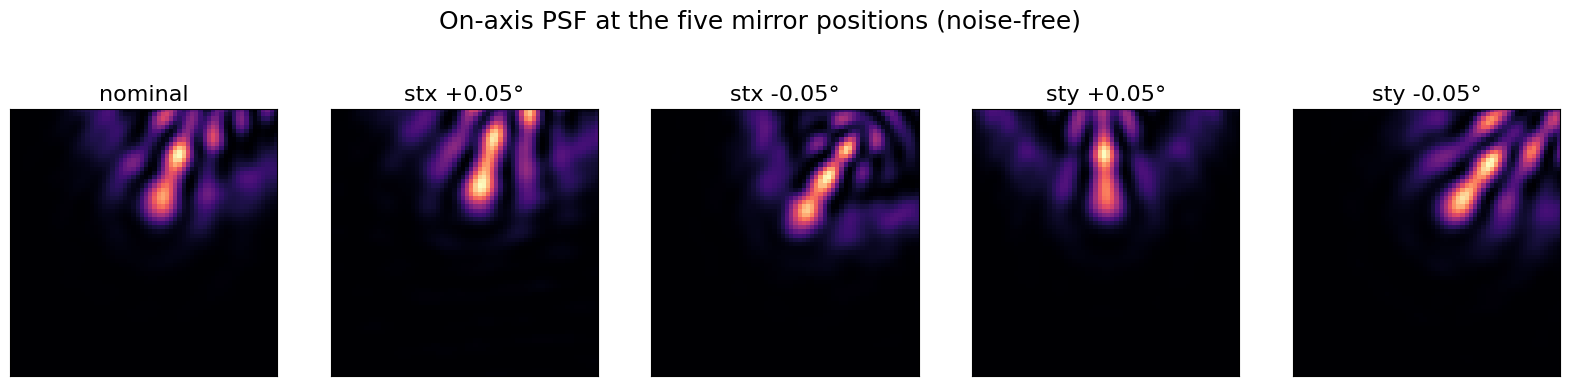

In [27]:
fig, axes = plt.subplots(1, len(MOVES), figsize=(20, 4.8))
for ax, d, label in zip(axes, MOVES, POSITIONS):
    t = truth + d
    psf = MMDFTPSF(hubble(sdx=t[0], sdy=t[1], sdz=t[2], stx=t[3], sty=t[4]), field=(0, 0), wavelength=0.55, grid_size=64).psf[96:160, 96:160]
    ax.imshow(psf, cmap='magma', origin='lower')
    ax.set_title(label, fontsize=16)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('On-axis PSF at the five mirror positions (noise-free)', fontsize=18)
plt.show()

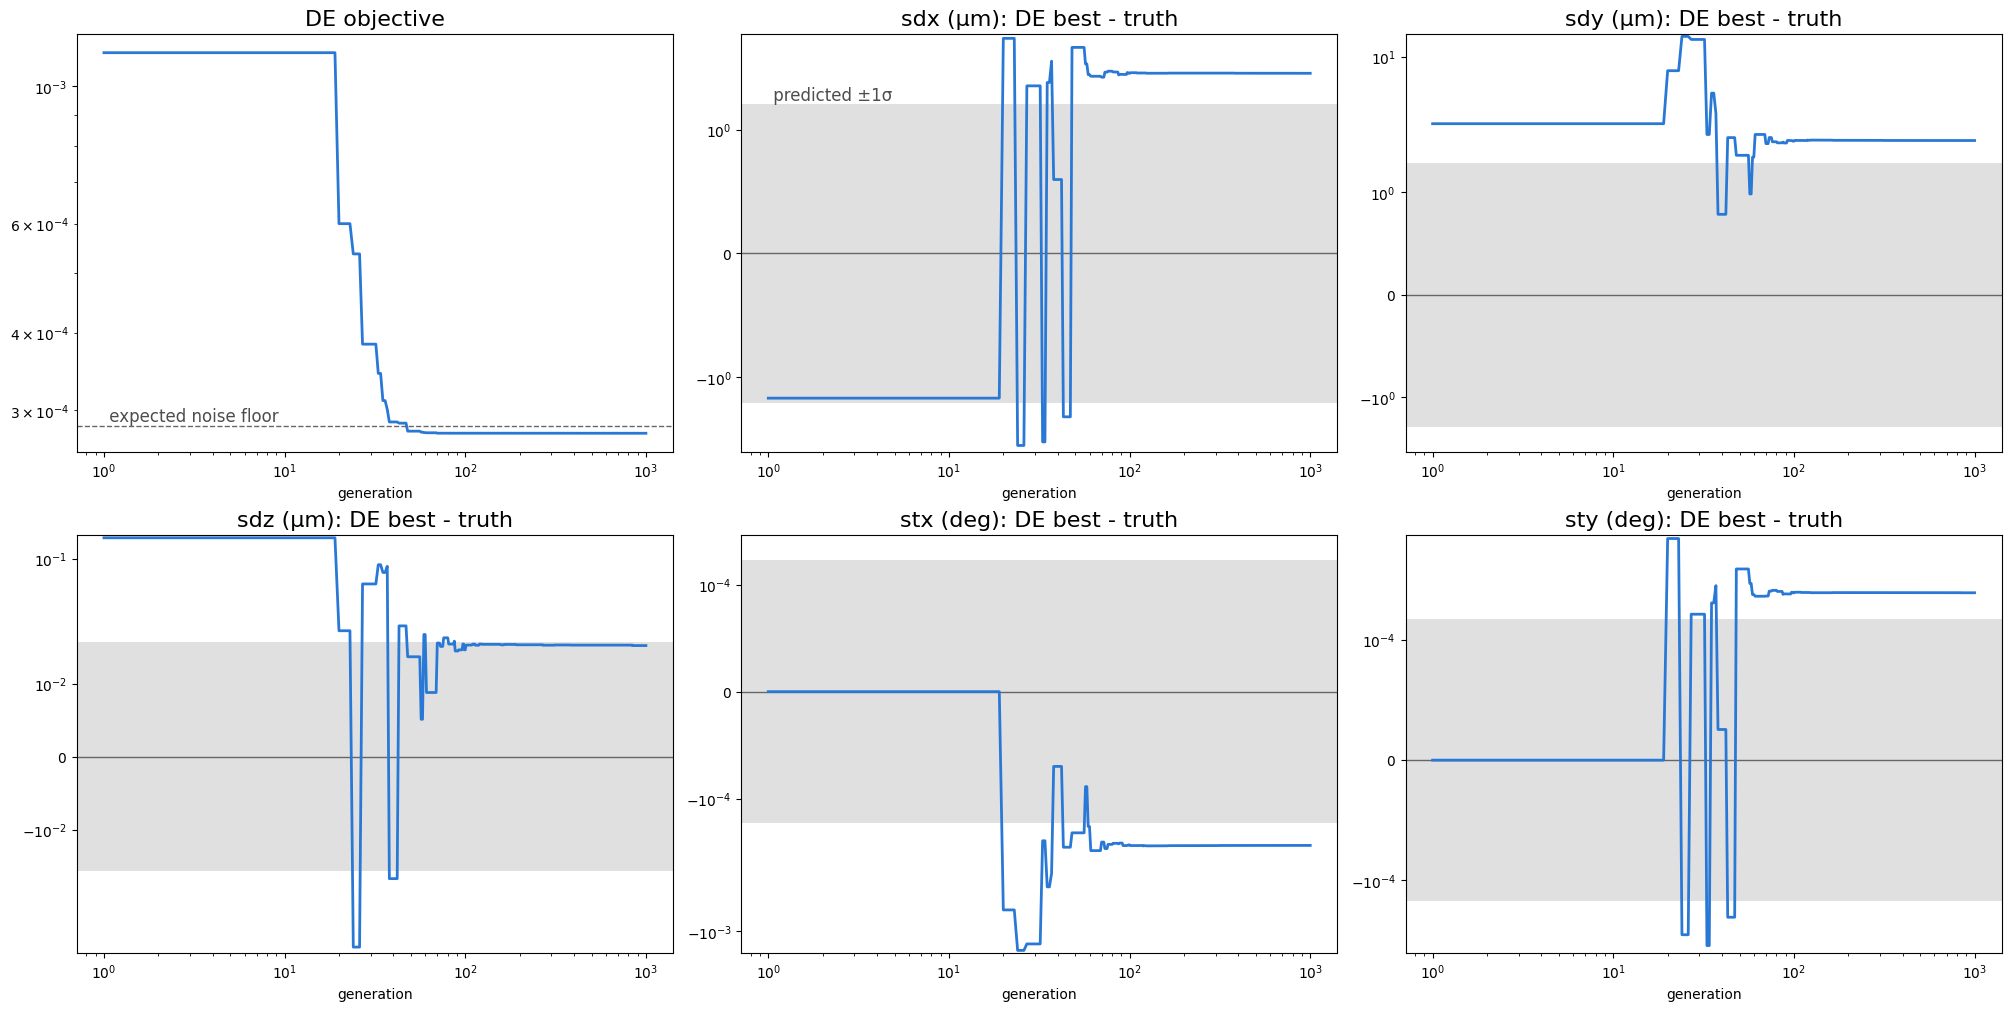

In [28]:
fun = np.array([h[0] for h in history])
X = np.array([h[1] for h in history])
gen = np.arange(1, len(fun) + 1)

fig, axes = plt.subplots(2, 3, figsize=(20, 10), constrained_layout=True)
ax = axes.flat[0]
ax.loglog(gen, fun, color='#2a78d6', lw=2)
ax.axhline(floor_moves, color='0.4', lw=1, ls='--')
ax.text(gen[0], floor_moves, ' expected noise floor', va='bottom', color='0.3', fontsize=12)
ax.set_title('DE objective', fontsize=16)
ax.set_xlabel('generation')
for ax, j, name in zip(axes.flat[1:], range(5), names):
    ax.axhspan(-sd_moves[j], sd_moves[j], color='0.88', lw=0)
    ax.axhline(0, color='0.4', lw=1)
    ax.plot(gen, X[:, j] - truth[j], color='#2a78d6', lw=2)
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=sd_moves[j])
    ax.set_title(f'{name}: DE best - truth', fontsize=16)
    ax.set_xlabel('generation')
axes.flat[1].text(gen[0], sd_moves[0], ' predicted ±1σ', va='bottom', color='0.3', fontsize=12)
plt.show()

In [29]:
pool.close()
pool.join()